# 9월 주문별 거리 비용 · 렉 방문 빈도와 대표 주문

2026-09-01~09-27 출고 요청, `SHIPPED`, 피킹 수량 양수만 사용합니다. 9/28~30 자료는 없습니다.
고객 주문번호 `orderId` 단위로 층·선반·수량·분할 출고의 같은 렉을 한 번으로 묶습니다.

**상대 거리 비용의 첫 계산**입니다. 실제 미터·작업시간·S자 경로가 아닙니다.
수직은 구역 안쪽 깊이, 수평은 옆으로 빠지는 이동을 뜻하며 선반 높이는 제외합니다.

- 출입 관계: A–B–패킹–C–D. A 방문 시 B04 출구도 포함합니다.
- 대표점: A07 앞 (17,13), B09 근처 (17,7), C05 앞 (1,10), B→A 출구 (0,13).
  인접 렉은 사용자 확인, 좌표는 계산용 근사입니다.
- `2×(상온 최대 깊이 + 냉장·냉동 최대 깊이) + 2×Σ max(0, 블록별 측방 최대 진입−τ)`.
- **진입 구간 j는 깊이별 진열 블록×위/아래로 묶습니다.** 같은 블록의 여러 렉 방문은 최대 범위만 셉니다.
- 기본 `τ=0`, 비교 `τ=2`. 도면 1칸은 동일 비용 1로 가정합니다. 연결·우회 추가 보정은 아직 0입니다.
- 위치 누락 주문은 거리 평균·최장 순위에서 제외합니다. 히트맵에는 전체 주문의 지도 표시 렉을 포함합니다.

[산식 설명](../docs/mfc_order_distance_model.md) · [설정](../references/mfc_layout/distance_model_2026-09.json)

전체 실행하면 `reports/mfc_order_distance/2026-09/`의 보고서·그림·CSV를 다시 생성합니다.

In [1]:
import pandas as pd
from IPython.display import Image, display
from hit_stocks_analysis import find_project_root
from hit_stocks_analysis.mfc_order_distance import build_report

ROOT = find_project_root()
result = build_report(ROOT)
summary = result["summary"]
orders = result["orders"]
folder = result["folder"]
print(folder)
display(pd.Series({
    "전체 주문": summary["orders"],
    "거리 통계 대상 주문": summary["complete_orders"],
    "위치 누락 제외 주문": summary["excluded_orders"],
    "평균 비용": summary["mean_cost"],
    "중앙값 비용": summary["median_cost"],
    "최대 비용": summary["max_cost"],
    "최대 비용 동률 주문 수": summary["max_order_count"],
}, name="결과").to_frame())

/Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/mfc_order_distance/2026-09


,결과
전체 주문,32650.000000
거리 통계 대상 주문,31061.000000
위치 누락 제외 주문,1589.000000
평균 비용,137.772478
중앙값 비용,135.500000
최대 비용,359.833333
최대 비용 동률 주문 수,1.000000


## 1. 전체 주문의 렉 방문 빈도

색은 **방문 주문 수(주문-렉 쌍)**이며 모든 구역이 같은 선형 척도입니다.
표의 `order_share_pct`는 해당 렉을 방문하는 주문 / 전체 주문 비율입니다.

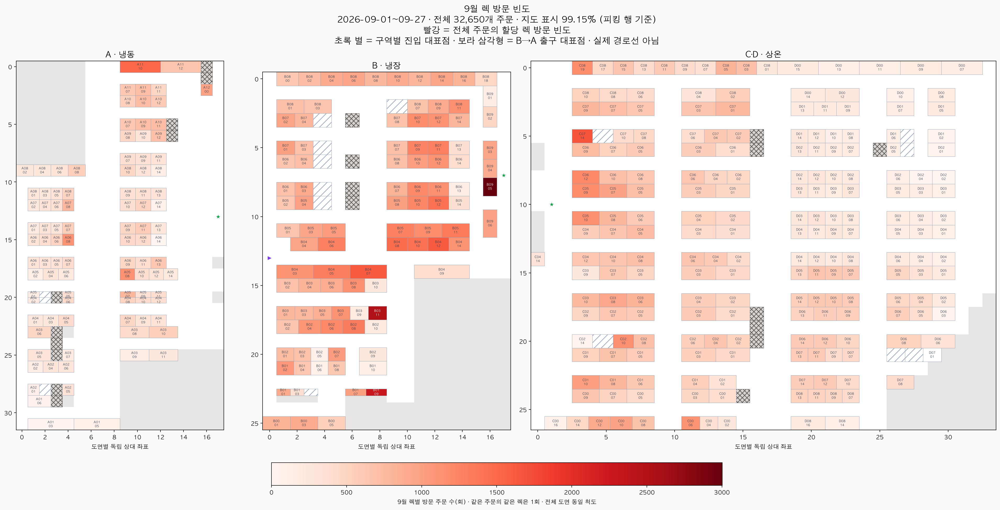

,order_visits,order_share_pct,area,aisle,rack
rack_code,,,,,
B09-05,3002,9.194487,B,09,05
B03-11,2513,7.696784,B,03,11
B01-09,2271,6.955590,B,01,09
C07-14,1667,5.105666,C_D,07,14
B04-12,1627,4.983155,B,04,12
B04-07,1614,4.943338,B,04,07
A11-10,1504,4.606432,A,11,10
B04-08,1468,4.496172,B,04,08
B04-10,1428,4.373660,B,04,10


In [2]:
display(Image(filename=str(folder / "rack_visit_heatmap.png"), width=1600))
display(result["counts"].nlargest(10, "order_visits")[["order_visits", "order_share_pct", "area", "aisle", "rack"]])

## 2. 가장 길게 계산된 주문

지도에 표시되는 파란 렉이 해당 주문의 방문 위치입니다. 경로·방문 순서는 추정하지 않습니다.
최대 동률 주문을 모두 기록하며, 그림은 요청 시각·주문번호 순으로 첫 주문을 선택합니다.

최대 비용 주문번호: ['4667936126']


,requested_at,pick_rows,distinct_racks,mapped_rows,split_count,unmapped_rows,complete,ambient_depth,cold_depth,lateral_cost,depth_cost,known_rack_cost,distance_cost,cost_rank,cost_tau2
order_id,,,,,,,,,,,,,,,
4667936126,2026-09-25 18:10:56,31,31,31,2,0,True,25.5,30.166667,248.5,111.333333,359.833333,359.833333,1.0,303.833333


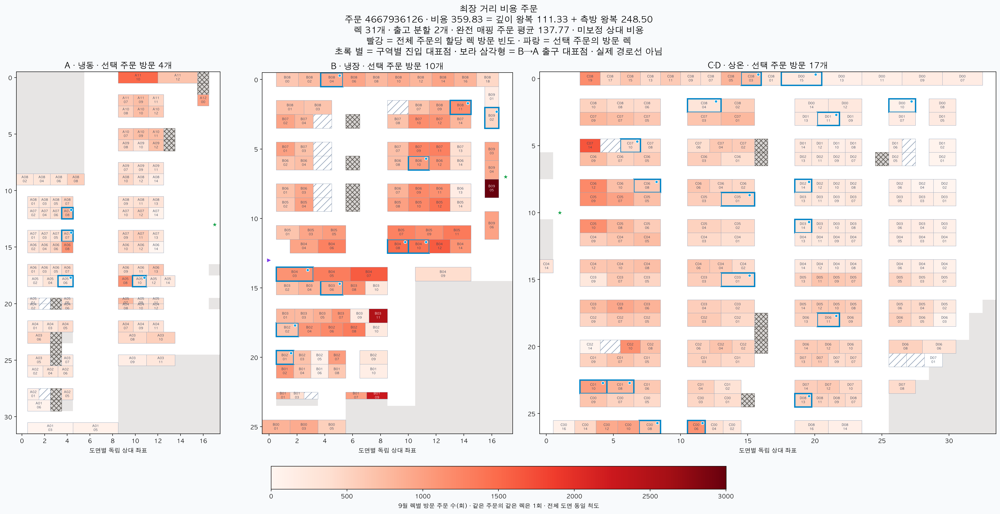

,rack_code,location_code,sku_name,picking_quantity,split_order_id
0,A05-06,A05-06-203,느솜 저당 단호박듬뿍 설기 50g×6개입,1,305978058
1,A05-10,A05-10-701,프로즌 원팩 마라 떡볶이 440g,1,305978058
2,A07-07,A07-07-402,[배민이지] 든든한 김치볶음밥 300g,3,305978058
3,A07-08,A07-08-304,[배민이지] 든든한 새우볶음밥 300g,3,305978058
4,B02-01,B02-01-205,호주청정우 갈비살 구이용 200g,1,305978058
5,B02-02,B02-02-103,THE듬뿍 양념 돼지 칼집 왕구이 1kg,1,305978058
6,B03-06,B03-06-104,프리미엄 Fresh 친환경 당근 500g,1,305978058
7,B04-03,B04-03-106,목우촌 국내산 훈제오리 450g (150g×3),1,305978058
8,B04-08,B04-08-208,국내산 애호박 1개(18cm 이상),1,305978058
9,B04-10,B04-10-305,디엠지 친환경 햇양파 1kg,1,305978058


In [3]:
print("최대 비용 주문번호:", summary["max_order_ids"])
display(orders.loc[summary["max_order_ids"]])
display(Image(filename=str(folder / "longest_order.png"), width=1600))
longest_locations = pd.read_csv(folder / "longest_order_locations.csv", dtype={"order_id": str, "split_order_id": str})
display(longest_locations[["rack_code", "location_code", "sku_name", "picking_quantity", "split_order_id"]])

## 3. 평균 거리 비용과 대표 주문 10개

완전 매핑 주문의 산술평균에 비용이 가장 가까운 **실제 주문 10개**를 표시합니다.
평균과의 절대 차이 → 요청 시각 → 주문번호 순으로 선정합니다.
방문 조합의 다양성을 기준으로 뽑은 표본이나 전체 주문의 평균 위치는 아닙니다.

평균 비용: 137.772478


,representative_rank,order_id,requested_at,distance_cost,mean_gap,distinct_racks,depth_cost,lateral_cost,rack_codes
314,1,4662746695,2026-09-01 13:18:17,137.75,0.022478,5,67.75,70.0,"B00-03, B03-06, C05-10, D01-14, D07-11"
4407,2,4663506007,2026-09-05 08:56:14,137.75,0.022478,8,65.25,72.5,"B00-03, B01-07, B02-06, B04-12, B09-02, C05-07..."
11235,3,4664726296,2026-09-10 19:14:13,137.75,0.022478,6,73.75,64.0,"A04-10, A05-08, B03-08, B07-08, B08-11, C02-04"
11998,4,4664875429,2026-09-11 15:58:43,137.75,0.022478,6,83.75,54.0,"A11-10, B05-10, B05-11, B07-07, C04-05, D03-14"
13328,5,4665121887,2026-09-12 16:09:26,137.75,0.022478,7,71.75,66.0,"B01-02, B02-02, B02-08, B03-07, B04-14, B05-04..."
13511,6,4665152799,2026-09-12 17:43:15,137.75,0.022478,7,71.75,66.0,"B01-02, B02-01, B07-09, B07-12, B07-14, B08-12..."
14441,7,4665322186,2026-09-13 12:03:01,137.75,0.022478,7,71.75,66.0,"B01-07, B05-03, B07-09, B07-10, B07-11, D07-07..."
17193,8,4665808698,2026-09-15 16:05:43,137.75,0.022478,6,71.75,66.0,"B01-02, B02-03, B06-07, B07-11, B08-04, D06-11"
18658,9,4666078597,2026-09-16 21:22:14,137.75,0.022478,6,71.75,66.0,"B01-02, B01-08, B05-09, C07-14, C08-15, D01-11"
20288,10,4666404841,2026-09-18 17:31:28,137.75,0.022478,5,107.75,30.0,"A08-03, B03-05, C05-07, D04-08, D04-11"


대표 1: 주문 4662746695 · 비용 137.75 · 렉 5개


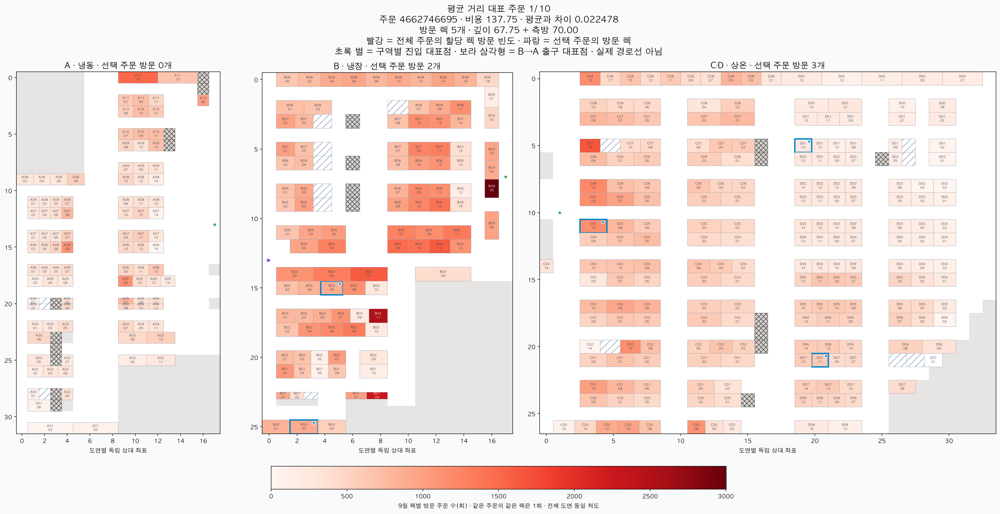

대표 2: 주문 4663506007 · 비용 137.75 · 렉 8개


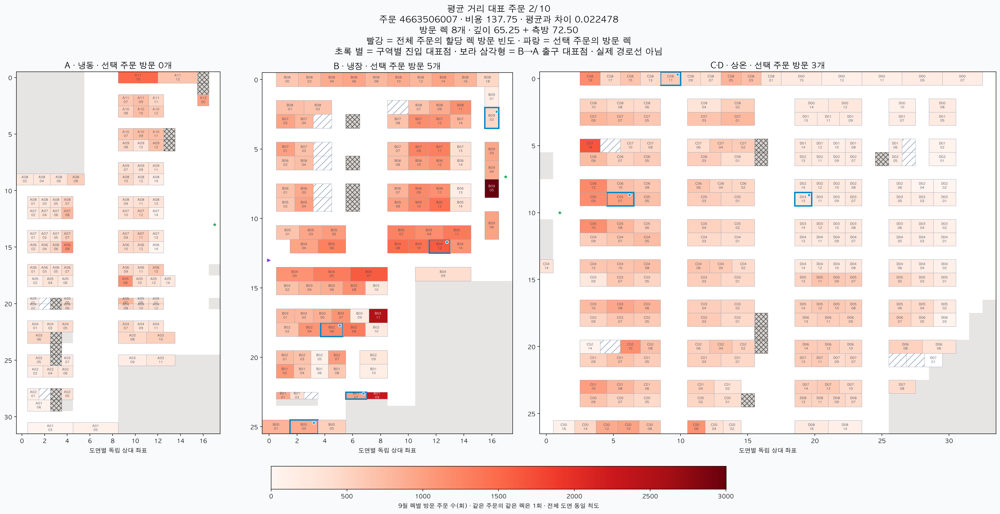

대표 3: 주문 4664726296 · 비용 137.75 · 렉 6개


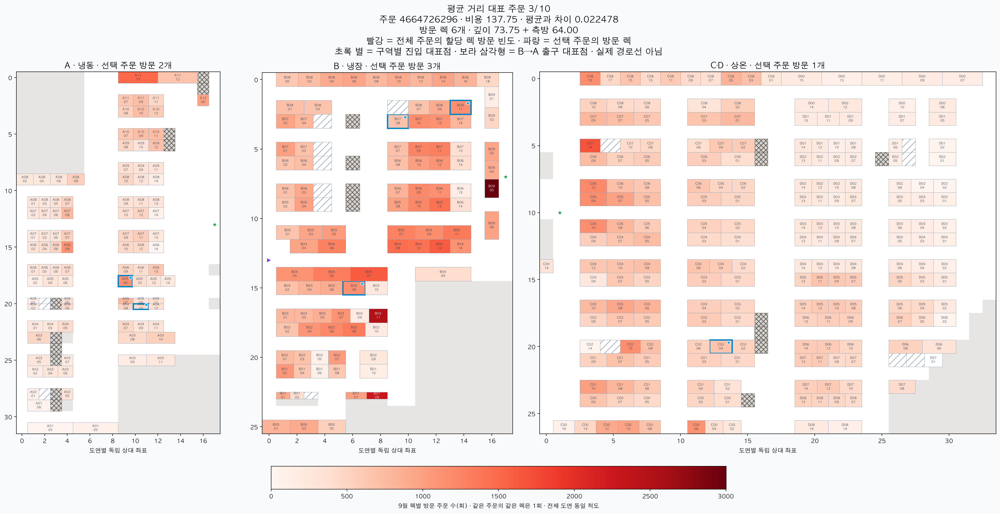

대표 4: 주문 4664875429 · 비용 137.75 · 렉 6개


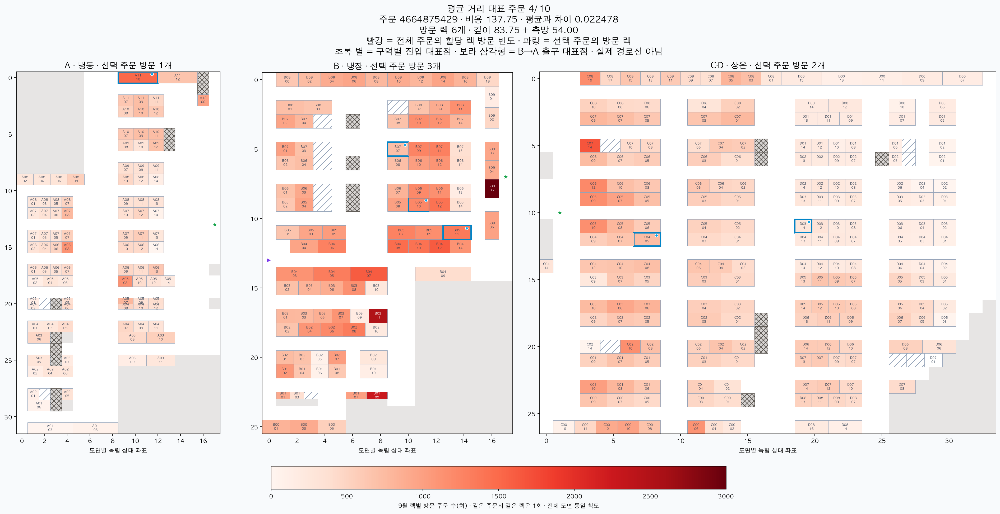

대표 5: 주문 4665121887 · 비용 137.75 · 렉 7개


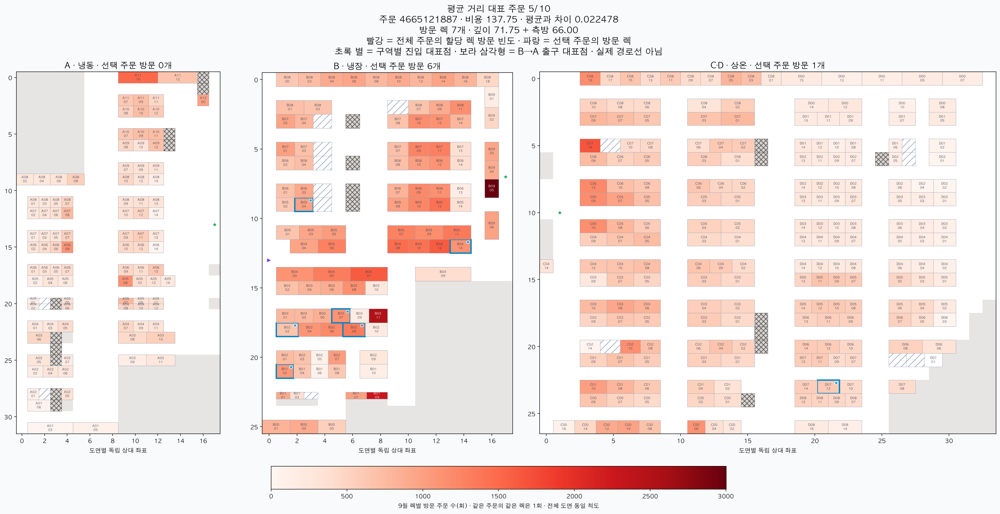

대표 6: 주문 4665152799 · 비용 137.75 · 렉 7개


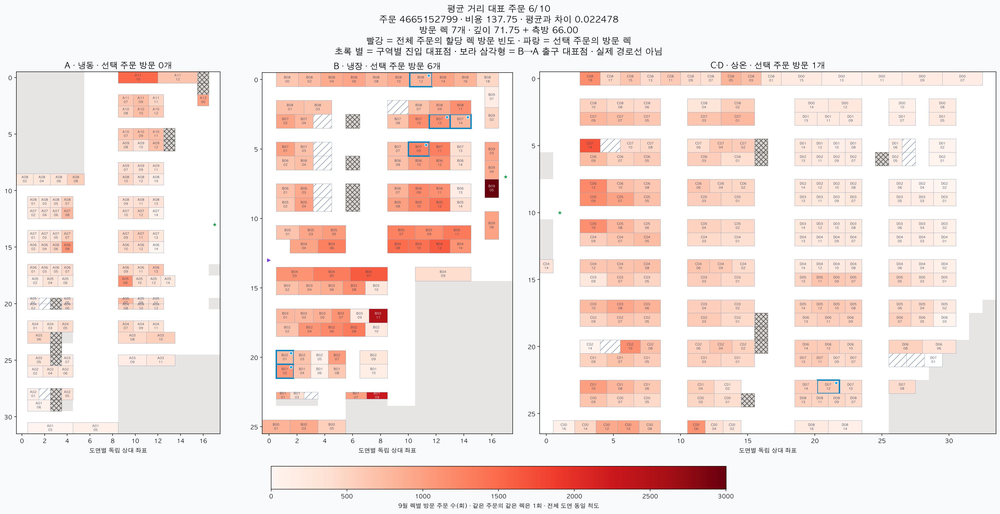

대표 7: 주문 4665322186 · 비용 137.75 · 렉 7개


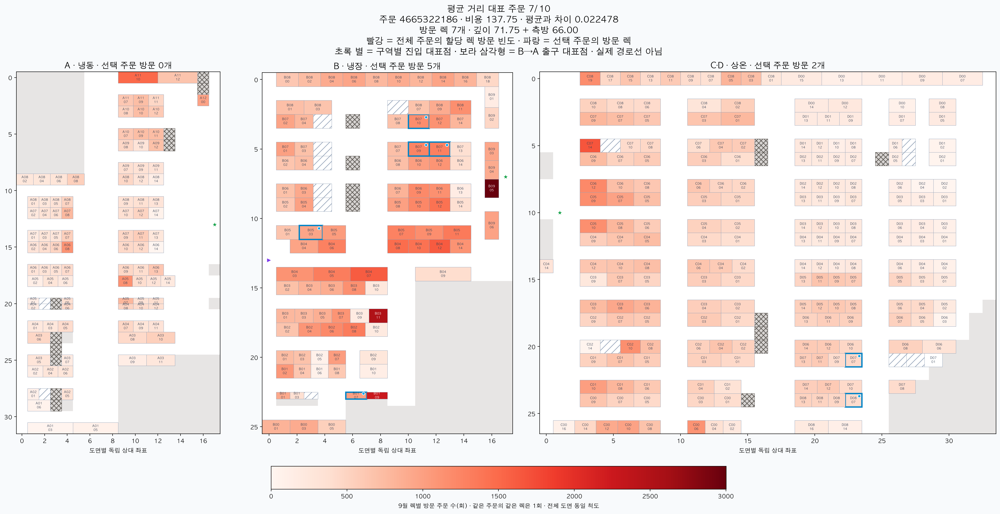

대표 8: 주문 4665808698 · 비용 137.75 · 렉 6개


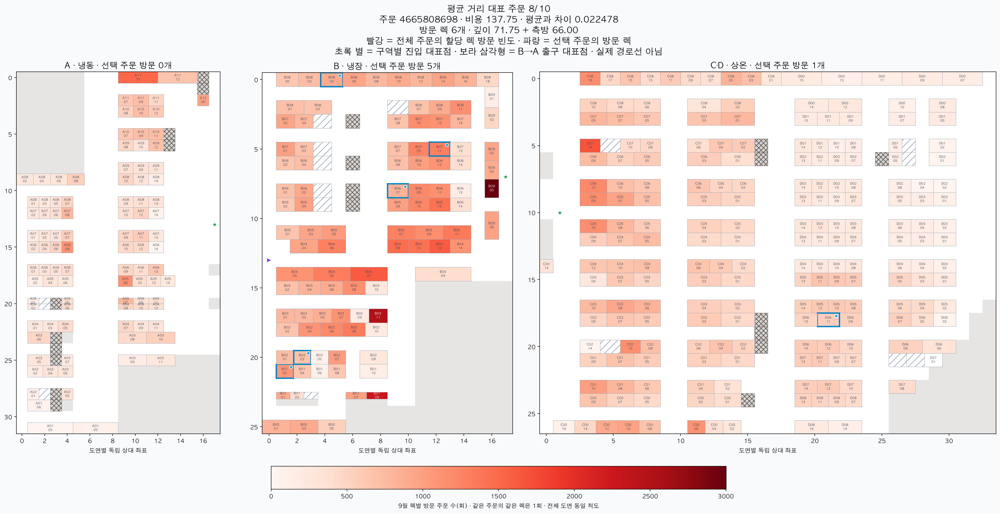

대표 9: 주문 4666078597 · 비용 137.75 · 렉 6개


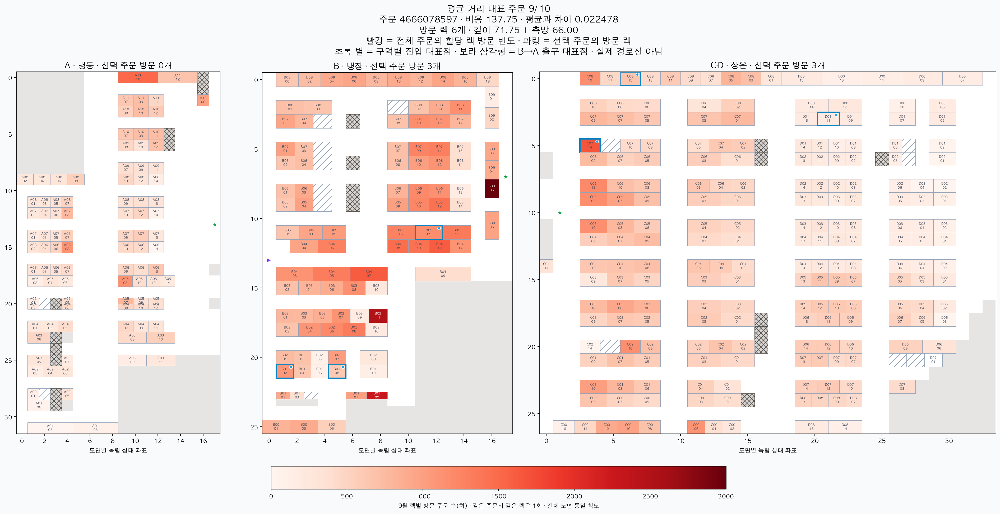

대표 10: 주문 4666404841 · 비용 137.75 · 렉 5개


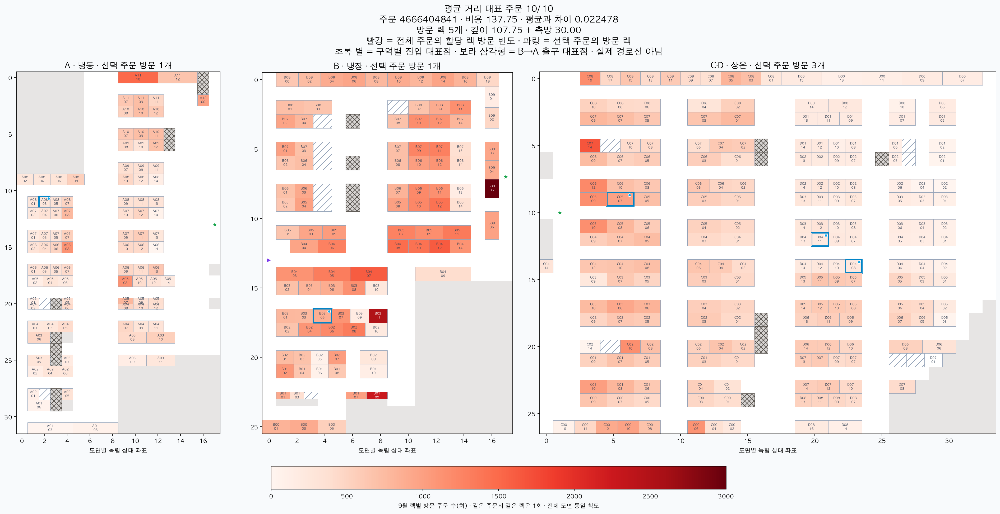

지도 모음: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/mfc_order_distance/2026-09/mean_representatives.md
상품별 방문 위치: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/mfc_order_distance/2026-09/mean_representative_locations.csv


In [4]:
print(f"평균 비용: {summary['mean_cost']:.6f}")
mean_orders = result["mean_orders"]
display(mean_orders[["representative_rank", "order_id", "requested_at", "distance_cost",
                     "mean_gap", "distinct_racks", "depth_cost", "lateral_cost", "rack_codes"]])
for row in mean_orders.itertuples(index=False):
    print(f"대표 {row.representative_rank}: 주문 {row.order_id} · 비용 {row.distance_cost:.2f} · 렉 {row.distinct_racks}개")
    path = folder / "mean_representatives" / f"{row.representative_rank:02}_{row.order_id}.png"
    display(Image(filename=str(path), width=1600))
print("지도 모음:", folder / "mean_representatives.md")
print("상품별 방문 위치:", folder / "mean_representative_locations.csv")

## 4. 분포·생략 기준 비교·누락

`τ=2`는 짧은 측방 이동을 생략하는 가상 비교입니다. 현장 보정값으로 확정한 값이 아닙니다.
분할 출고 여러 건도 한 고객 주문으로 묶었으며, 분할별 추가 왕복은 포함하지 않습니다.

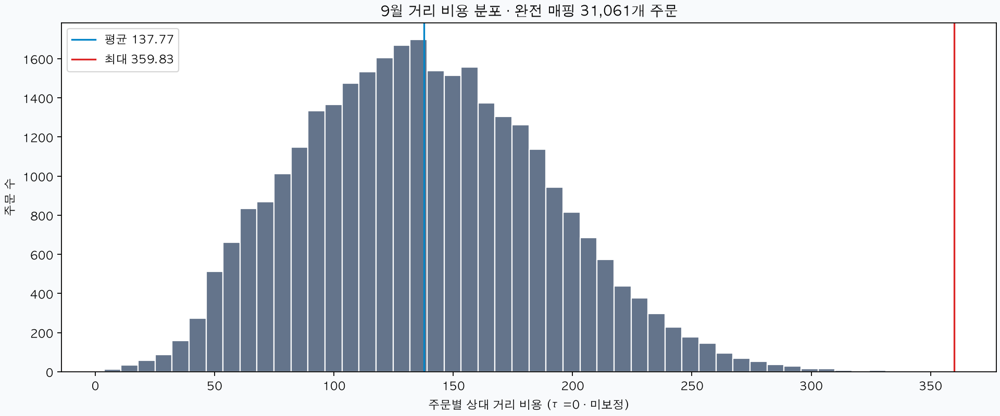

,tau,orders,mean_cost,max_cost,max_order_id
0,0,31061,137.772478,359.833333,4667936126
1,2,31061,119.890450,303.833333,4667936126


,order_id,requested_at,pick_rows,distinct_racks,mapped_rows,split_count,unmapped_rows,complete,ambient_depth,cold_depth,lateral_cost,depth_cost,known_rack_cost,distance_cost,cost_rank,cost_tau2,mean_gap
0,4667936126,2026-09-25 18:10:56,31,31,31,2,0,True,25.500000,30.166667,248.500000,111.333333,359.833333,359.833333,1.0,303.833333,222.060856
1,4663521900,2026-09-05 10:24:09,20,19,20,1,0,True,28.500000,30.000000,230.000000,117.000000,347.000000,347.000000,2.0,303.000000,209.227522
2,4668221355,2026-09-26 23:59:12,26,23,26,4,0,True,27.000000,33.000000,226.000000,120.000000,346.000000,346.000000,3.0,298.000000,208.227522
3,4663239743,2026-09-03 19:09:26,25,24,25,1,0,True,28.666667,32.000000,214.000000,121.333333,335.333333,335.333333,4.0,283.333333,197.560856
4,4665715703,2026-09-14 22:39:50,31,27,31,2,0,True,25.333333,32.250000,220.000000,115.166667,335.166667,335.166667,5.0,287.166667,197.394189
5,4666623418,2026-09-19 16:08:40,23,22,23,2,0,True,27.000000,32.500000,213.666667,119.000000,332.666667,332.666667,6.0,279.000000,194.894189
6,4665565431,2026-09-14 11:21:23,26,25,26,1,0,True,27.000000,31.500000,214.500000,117.000000,331.500000,331.500000,7.0,279.500000,193.727522
7,4665870896,2026-09-15 20:01:22,18,16,18,1,0,True,27.000000,31.500000,212.000000,117.000000,329.000000,329.000000,8.0,289.000000,191.227522
8,4663174239,2026-09-03 14:44:53,32,29,32,2,0,True,25.333333,33.000000,212.000000,116.666667,328.666667,328.666667,9.0,280.666667,190.894189
9,4663685730,2026-09-05 20:53:16,20,20,20,2,0,True,27.000000,32.250000,208.000000,118.500000,326.500000,326.500000,10.0,278.500000,188.727522


위치 누락 로케이션 상위 15개


,rack_code,location_code,pick_rows,orders
18,M01-01,M01-01-301,224,216
12,M01-01,M01-01-105,112,110
36,M01-01,M01-01-508,109,107
39,S01-01,S01-01-201,100,98
20,M01-01,M01-01-305,93,91
15,M01-01,M01-01-204,90,88
42,S01-01,S01-01-204,80,80
27,M01-01,M01-01-405,77,76
40,S01-01,S01-01-202,69,69
6,C08-00,C08-00-302,62,60


전체 결과: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/mfc_order_distance/2026-09/summary.md


In [5]:
display(Image(filename=str(folder / "cost_distribution.png"), width=1100))
display(result["sensitivity"])
display(pd.read_csv(folder / "top20_orders.csv", dtype={"order_id": str}))
print("위치 누락 로케이션 상위 15개")
display(pd.read_csv(folder / "unmapped_locations.csv").nlargest(15, "pick_rows"))
print("전체 결과:", folder / "summary.md")